In [2]:
#Importing needed libraries/modules
import numpy as np
import math
from numpy import random
import matplotlib.pyplot as plt

In [3]:


#Defining the arrays of equity and bond returns. These arrays have M rows, representing M possible investment futures, 
#and N+1 columns representing a time period of N years (the first column represents the start of a given investment 
#future, the second column represents the end of the first year, the third column represents the end of the second year, etc.).
#As well as being a function of M and N, these arrays are functions of mu_B (the expected yearly return on bonds), 
#sigma_B (the standard deviation in the yearly return on bonds), mu_E (the equity drift), sigma_E (the equity volatility parameter).
# The values in these arrays use randomly generated normal distribution numbers.

def R_E_R_B_array(M,N,mu_B,sigma_B,mu_E,sigma_E):
    R_B = random.normal(loc= mu_B, scale= sigma_B, size = (M, N+1)) #Modelling the yearly bond returns as a normal distribution
    Z_N = random.normal(loc = 0, scale = 1, size = (M, N+1))
    I = np.exp((mu_E-((1/2)*((sigma_E)**2)))+(sigma_E*Z_N)) #The distribution for the factor by which the bond investments multiply by each year
    R_E = I - 1
    return R_E, R_B


#Defining the function that works out the present value of all future liabilites. This depends on p ( p = one more than the number of years 
#left in the investment future), r (yearly liability discount rate) and L (yearly liability payments)
def s(p,r,L):
    s = 0
    for l in range (1, p): 
        s = s + (L/((1+r)**l))
    return s


#Defining the function that will produce the arrays containing the assets and surplus values. As well as M, N, L and r, it inputs A_0
#(intial assets), w (proportion of assets invested in equities), R_E (the already generated equity returns array) and R_B (the already
#generated bond returns array)

def combined_array(M,N,A_0,L,w,R_E,R_B,r): 
    
    A_array = np.zeros((M,N+1))
    S_array = np.zeros((M,N+1))
    A_array[:,0] = A_0
    R_P = np.zeros((M,N+1))
    A = np.zeros((M,N+1))
    A[:,0] = A_0

    #Calculating the surplus at the start of each investment future
    S_array[:,0] = A_0 - s(N+1,r,L)

    R_P = w*R_E + (1-w)*R_B #Overall yearly returns array
    for i in range (1, N+1) :
        A[:,i] = ((A[:,i-1])*(1 + R_P[:,i])) - L #Multiplying the assets by the yearly overall returns, and taking off the yearly liability payment L
        
        #Generating the assets array A_array and surplus array S_array.
        #Making the corresponding assets array values equal to the assets in a given year and investment future if it is positive. If the
        #assets in a given year are negative, keeping that value and all values in the same row and higher column number
        #in the assets array equal to zero (since the company has gone bankrupt and there are no assets left for that year and all future years in that
        #investment future). Making the surplus array values equal to the corresponding asset values (in the same row and column) - the 
        #value of outstanding/unpaid payments in that year
        positive = A[:, i] > 0
        A_array[positive, i] = A[positive, i]
        S_array[positive,i] = A[positive, i] - s(N+1-i,r,L)
        A_array[~positive,i] = 0
        S_array[~positive,i] = A[~positive,i - np.sum(A_array[~positive,:i]==0, axis = 1) ] - s(N+1-i,r,L) - (L*(np.sum(A_array[~positive,:i]==0, axis = 1)))
                

    return A_array,S_array
    

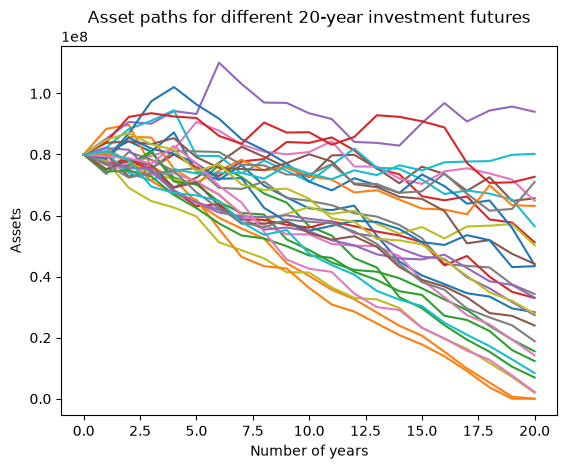

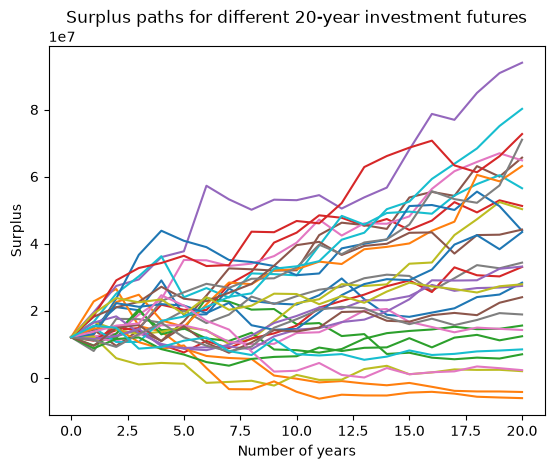

In [7]:
#Defining values for each variable in the function which generates the assets and surplus arrays
M = 30
N = 20
A_0 = 80000000
L = 5000000
w = 0.2
mu_B = 0.035
sigma_B = 0.05
mu_E = 0.07
sigma_E = 0.18
r = 0.04


#Plotting the assets and surplus arrays against the number of years since the start of the investment, one row (investment future) at a time 
R_E, R_B = R_E_R_B_array(M,N,mu_B,sigma_B,mu_E,sigma_E)
A_array_1, S_array_1 = combined_array(M,N,A_0,L,w,R_E,R_B,r)
n = np.arange(0,N+1,1)
for q in range (0,M):
    plt.plot(n,A_array_1[q,:])
    plt.xlabel("Number of years")
    plt.ylabel("Assets")
    plt.title("Asset paths for different 20-year investment futures")
plt.show()
for t in range (0,M):
    plt.plot(n,S_array_1[t,:])
    plt.xlabel("Number of years")
    plt.ylabel("Surplus")
    plt.title("Surplus paths for different 20-year investment futures")
plt.show()



In [51]:
#Monte Carlo simulation for M = 100000 possible investment futures to estimate the probabilities that: 1. The assets fall below £0, making the
#pension company go bankrupt and 2. The surplus, at some point, falls below zero.

def fraction_negative(M,N,A_0,L,w,R_E,R_B,r): #Function producing 1. The estimated proportion of investment futures that leads to bankruptcy.
#2.The estimated proportion of investment futures leading to negative surplus
    count_assets_positive = 0
    count_surplus_positive = 0
    A_array_2, S_array_2 = combined_array(M,N,A_0,L,w,R_E,R_B,r)

    for p in range (M):
        cond_assets = A_array_2[p,N] #Checking the last value of each row of the assets array to check whether or not it is 0 (a value of 0 means bankruptcy)
        outcome_assets = 0 if cond_assets == 0 else 1
        count_assets_positive += outcome_assets
        l = 0
        while l <= N: #Creating a loop that checks every element of each row (investment future) of the surplus array to check whether or not 
        #there is at least one negative value
            if S_array_2[p,l] > 0:
                outcome_surplus = 1
                l += 1
            else:
                outcome_surplus = 0
                l = N + 1 
        count_surplus_positive += outcome_surplus
    #Calculating and printing the proportion of the simulated investment futures that lead to negative assets or surplus at any point
    fraction_assets_positive = count_assets_positive/M
    fraction_surplus_positive = count_surplus_positive/M
    fraction_assets_negative = 1 - fraction_assets_positive
    fraction_surplus_negative = 1 - fraction_surplus_positive
    return fraction_assets_negative, fraction_surplus_negative


M = 100000
R_E, R_B = R_E_R_B_array(M,N,mu_B,sigma_B,mu_E,sigma_E)
fraction_assets_negative, fraction_surplus_negative = fraction_negative(M,N,A_0,L,w,R_E,R_B,r)
print("Proportion of investment futures leading to bankruptcy =",round(fraction_assets_negative,5))
print("Proportion of investment futures leading to negative surplus =",round(fraction_surplus_negative,5))


Proportion of investment futures leading to bankruptcy = 0.10046
Proportion of investment futures leading to negative surplus = 0.16601


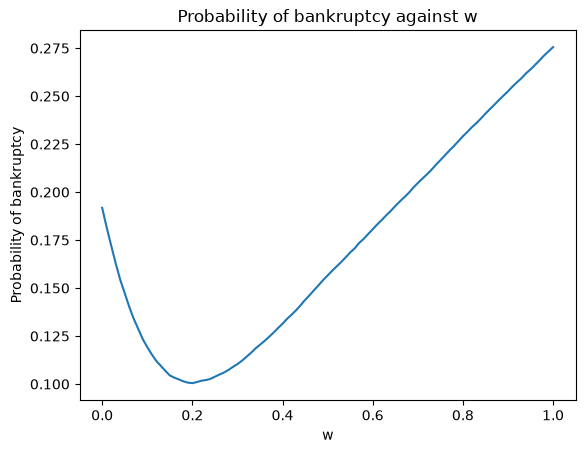

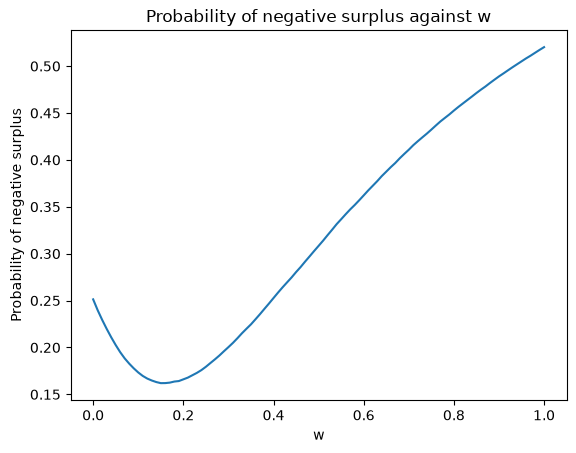

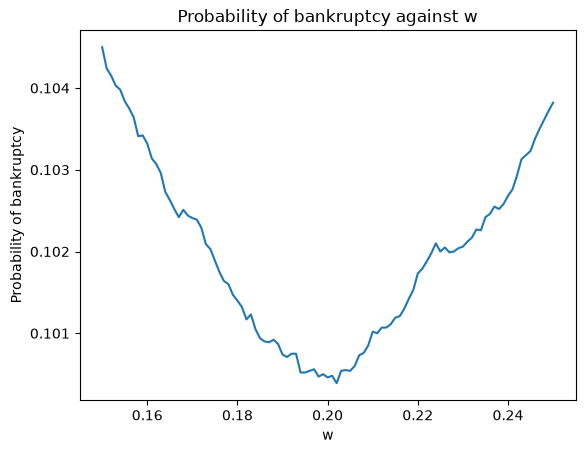

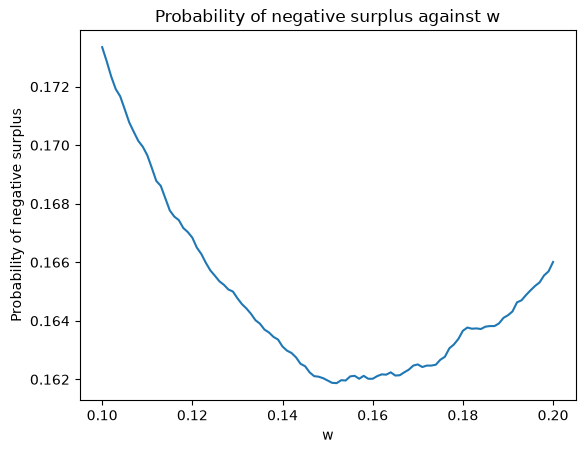

In [53]:
#Defining a function that can return the estimated probability of bankruptcy or negative surplus over multiple ranges of w values
def changing_w_arrays(M,N,A_0,L,R_E,R_B,r,n): 
    w = 0
    w_array = np.zeros(n+1)
    w_array_1 = np.zeros(n+1)
    w_array_2 = np.zeros(n+1)
    fraction_assets_negative_array = np.zeros(n+1)
    fraction_surplus_negative_array = np.zeros(n+1)
    fraction_assets_negative_array_1 = np.zeros(n+1)
    fraction_surplus_negative_array_1 = np.zeros(n+1)

    for i in range (n+1):
        w_array[i] = w
        fraction_assets_negative, fraction_surplus_negative = fraction_negative(M,N,A_0,L,w,R_E,R_B,r)
        fraction_assets_negative_array[i] = fraction_assets_negative
        fraction_surplus_negative_array[i] = fraction_surplus_negative
        w += 1/n
    

    w = 0.15
    for i in range (n+1):
        w_array_1[i] = w
        fraction_assets_negative, fraction_surplus_negative = fraction_negative(M,N,A_0,L,w,R_E,R_B,r)
        fraction_assets_negative_array_1[i] = fraction_assets_negative
        w  += 0.1/n
    w = 0.1
    for i in range (n+1):
        w_array_2[i] = w
        fraction_assets_negative, fraction_surplus_negative = fraction_negative(M,N,A_0,L,w,R_E,R_B,r)
        fraction_surplus_negative_array_1[i] = fraction_surplus_negative
        w += 0.1/n
    return w_array, fraction_assets_negative_array, fraction_surplus_negative_array, w_array_1, fraction_assets_negative_array_1, w_array_2, fraction_surplus_negative_array_1

n = 100
w_array, fraction_assets_negative_array, fraction_surplus_negative_array, w_array_1, fraction_assets_negative_array_1, w_array_2, fraction_surplus_negative_array_1 = changing_w_arrays(M,N,A_0,L,R_E,R_B,r,n)

#Plotting the graphs
plt.plot(w_array,fraction_assets_negative_array)
plt.xlabel("w")
plt.ylabel("Probability of bankruptcy")
plt.title("Probability of bankruptcy against w")
plt.show()

plt.plot(w_array,fraction_surplus_negative_array)
plt.xlabel("w")
plt.ylabel("Probability of negative surplus")
plt.title("Probability of negative surplus against w")
plt.show()

plt.plot(w_array_1,fraction_assets_negative_array_1)
plt.xlabel("w")
plt.ylabel("Probability of bankruptcy")
plt.title("Probability of bankruptcy against w")
plt.show()

plt.plot(w_array_2,fraction_surplus_negative_array_1)
plt.xlabel("w")
plt.ylabel("Probability of negative surplus")
plt.title("Probability of negative surplus against w")
plt.show()
    


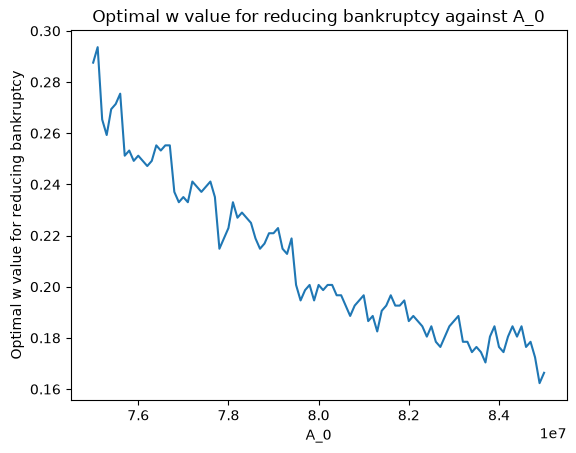

Text(0.5, 1.0, 'Optimal w value for reducing negative surplus against A_0')

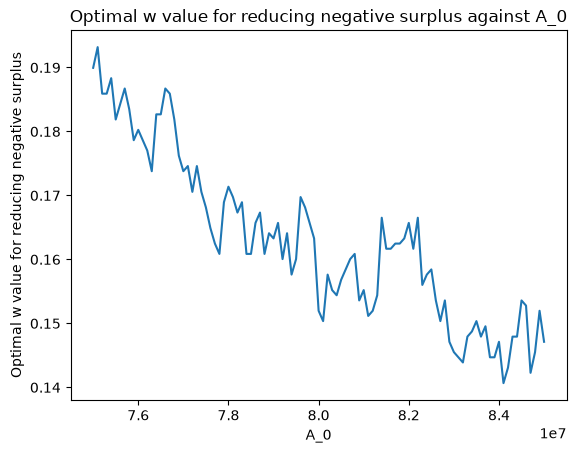

In [57]:

#Defining a function that inputs a chosen array of w values w_array and returns the w value with 1.The smallest chance of bankruptcy and 2.The smallest chance of negative surplus
def argmin_w_array(M, N, A_0, L, R_E, R_B, r, w_array):

    fraction_assets = np.zeros(len(w_array))
    fraction_surplus = np.zeros(len(w_array))

    for i, w in enumerate(w_array):
        fraction_assets[i], fraction_surplus[i] = fraction_negative(M, N, A_0, L, w, R_E, R_B, r)

    argmin_assets = np.argmin(fraction_assets)
    argmin_surplus = np.argmin(fraction_surplus)

    return w_array[argmin_assets], w_array[argmin_surplus]

A_0 = 75000000
k = 100

#Changing A_0, then plotting optimal w (for avoiding both bankruptcy and negative surplus) against A_0
changing_A_0_array = np.linspace(75000000, 85000000, k+1) 
min_w_array_assets = np.zeros(k+1)
min_w_array_surplus = np.zeros(k+1)
w_array = np.linspace(0.13,0.33,100)
for i, A_0 in enumerate(changing_A_0_array):
    min_w_array_assets[i], _ = argmin_w_array(M,N,A_0,L,R_E,R_B,r,w_array)
w_array_1 = np.linspace(0.135,0.215,100)
for i, A_0 in enumerate (changing_A_0_array):
    _, min_w_array_surplus[i]= argmin_w_array(M,N,A_0,L,R_E,R_B,r,w_array_1)


plt.plot(changing_A_0_array, min_w_array_assets)
plt.xlabel("A_0")
plt.ylabel("Optimal w value for reducing bankruptcy")
plt.title("Optimal w value for reducing bankruptcy against A_0")
plt.show()

plt.plot(changing_A_0_array, min_w_array_surplus)
plt.xlabel("A_0")
plt.ylabel("Optimal w value for reducing negative surplus")
plt.title("Optimal w value for reducing negative surplus against A_0")

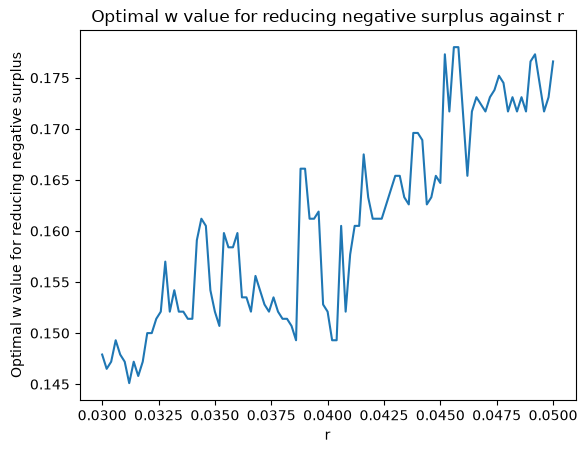

In [61]:
#Changing r and plotting optimal w for reducing negative surplus against r
A_0 = 80000000
m = 100
changing_r_array = np.linspace(0.03, 0.05, m+1)
min_w_array_surplus = np.zeros(m+1)
w_array_2 = np.linspace(0.115,0.185,m+1)
for i, r in enumerate(changing_r_array):
    _, min_w_array_surplus[i] = argmin_w_array(M,N,A_0,L,R_E,R_B,r,w_array_2)

plt.plot(changing_r_array, min_w_array_surplus)
plt.xlabel("r")
plt.ylabel("Optimal w value for reducing negative surplus")
plt.title("Optimal w value for reducing negative surplus against r")
plt.show()